# Experimentos EDA + Feature Engineering + Baseline + variantes
Datos simulados. Ejecutar en Google Colab y cargar el CSV.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from google.colab import files
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
uploaded=files.upload()
df=pd.read_csv(next(iter(uploaded)))
df['fecha']=pd.to_datetime(df['fecha'])
df=df.sort_values('fecha',kind='stable').reset_index(drop=True)
print('Forma:',df.shape,'Duplicados:',df.duplicated().sum())
display(df.isna().sum().to_frame('faltantes'))
display(df.describe(include='all').T)

Saving residuos_yarinacocha_2026.csv to residuos_yarinacocha_2026.csv
Forma: (733, 18) Duplicados: 3


,faltantes
fecha,0
codigo_ruta,0
vehiculo,0
sector,0
hora_salida,0
hora_llegada,0
duracion_min,0
distancia_km,0
combustible_l,6
costo_operativo_soles,4


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
fecha,733,NaN,NaN,NaN,2026-07-01 21:09:05.156889344,2026-01-01 00:00:00,2026-04-02 00:00:00,2026-07-02 00:00:00,2026-10-01 00:00:00,2026-12-31 00:00:00,NaN
codigo_ruta,733,6,R004,123,NaN,NaN,NaN,NaN,NaN,NaN,NaN
vehiculo,733,4,VH02,185,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sector,733,6,La Restinga,123,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hora_salida,733,62,06:13,21,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hora_llegada,733,212,10:10,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duracion_min,733.0,NaN,NaN,NaN,199.698499,150.0,160.0,191.0,225.0,431.0,44.273065
distancia_km,733.0,NaN,NaN,NaN,40.318172,21.76,35.85,39.85,45.08,60.27,6.789658
combustible_l,727.0,NaN,NaN,NaN,12.533232,7.07,10.965,12.34,14.055,23.27,2.379868
costo_operativo_soles,729.0,NaN,NaN,NaN,329.444993,216.4,294.51,323.35,361.71,554.39,52.277058


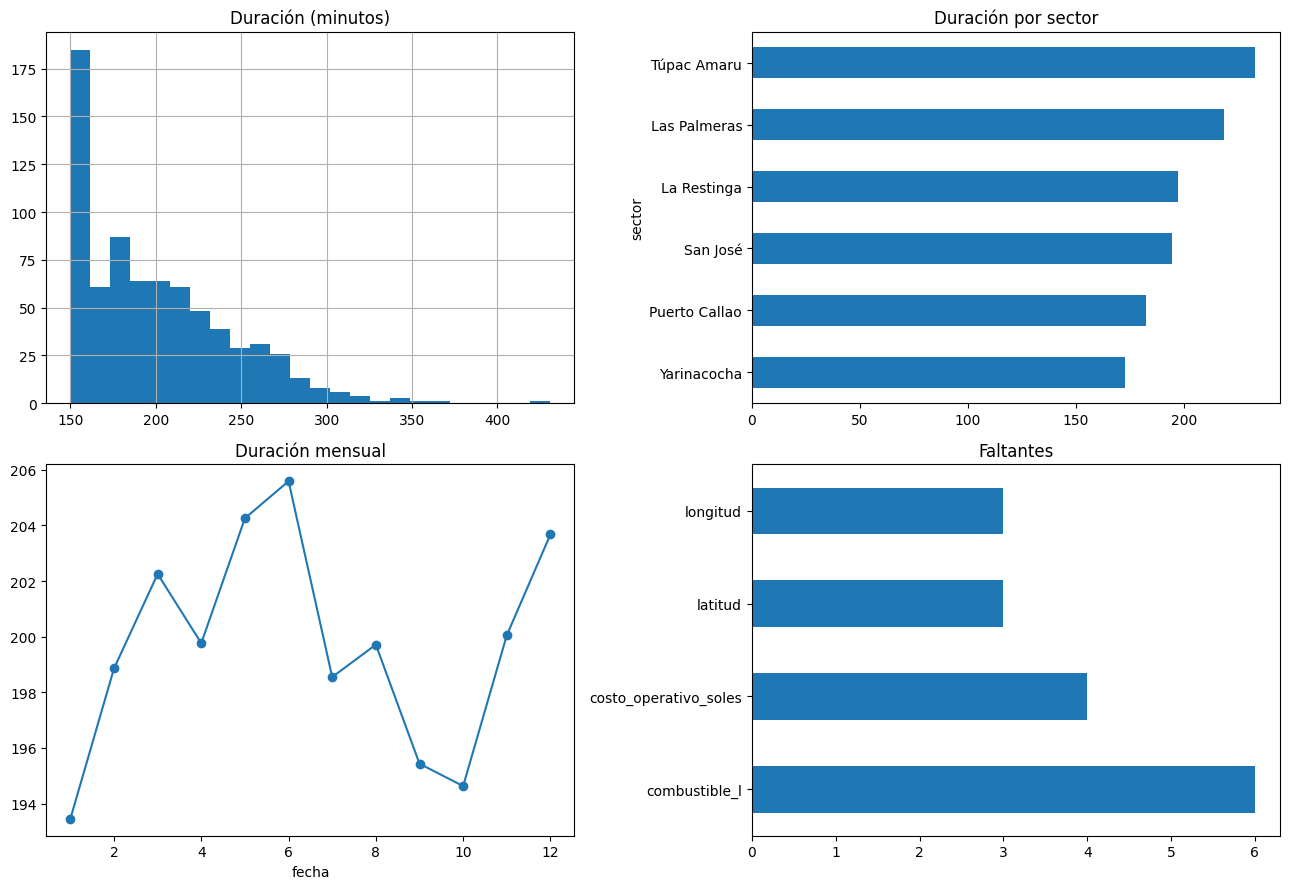

In [2]:
fig,axes=plt.subplots(2,2,figsize=(13,9))
df['duracion_min'].hist(bins=24,ax=axes[0,0]);axes[0,0].set_title('Duración (minutos)')
df.groupby('sector').duracion_min.mean().sort_values().plot.barh(ax=axes[0,1]);axes[0,1].set_title('Duración por sector')
df.groupby(df.fecha.dt.month).duracion_min.mean().plot(marker='o',ax=axes[1,0]);axes[1,0].set_title('Duración mensual')
df.isna().sum().loc[lambda s:s>0].plot.barh(ax=axes[1,1]);axes[1,1].set_title('Faltantes')
plt.tight_layout();plt.show()

In [4]:
fechas=np.sort(df.fecha.unique());c1=int(len(fechas)*.70);c2=int(len(fechas)*.85)
train=df[df.fecha.isin(fechas[:c1])].copy();val=df[df.fecha.isin(fechas[c1:c2])].copy();test=df[df.fecha.isin(fechas[c2:])].copy()
print(len(train),len(val),len(test))
# El mismo conjunto de validación para los tres experimentos

513 110 110


In [5]:
def transformar(d,modo):
    d=d.copy()
    if modo>=1:
        h=pd.to_datetime(d.hora_salida,format='%H:%M',errors='coerce')
        d['hora_salida_min']=h.dt.hour*60+h.dt.minute
    if modo>=2:
        d['mes']=d.fecha.dt.month
        d['dia_semana']=d.fecha.dt.dayofweek
        d['fin_semana']=(d.dia_semana>=5).astype(int)
        d['puntos_por_ton_cap']=d.puntos_programados/(d.capacidad_vehicular_kg/1000)
        d['hora_sin']=np.sin(2*np.pi*d.hora_salida_min/1440)
        d['hora_cos']=np.cos(2*np.pi*d.hora_salida_min/1440)
    return d
cat={0:['codigo_ruta','vehiculo','sector','hora_salida'],1:['codigo_ruta','vehiculo','sector'],2:['codigo_ruta','vehiculo','sector']}
num={0:['capacidad_vehicular_kg','puntos_programados'],1:['capacidad_vehicular_kg','puntos_programados','hora_salida_min'],2:['capacidad_vehicular_kg','puntos_programados','hora_salida_min','mes','dia_semana','fin_semana','puntos_por_ton_cap','hora_sin','hora_cos']}
def crear_modelo(i):
    pre=ColumnTransformer([('cat',Pipeline([('imp',SimpleImputer(strategy='most_frequent')),('oh',OneHotEncoder(handle_unknown='ignore'))]),cat[i]),('num',SimpleImputer(strategy='median'),num[i])])
    return Pipeline([('pre',pre),('rf',RandomForestRegressor(n_estimators=200,max_depth=12,min_samples_leaf=3,random_state=42,n_jobs=-1))])
def medir(y,p):return {'MAE':round(mean_absolute_error(y,p),3),'RMSE':round(np.sqrt(mean_squared_error(y,p)),3),'R2':round(r2_score(y,p),4)}

,Experimento,MAE,RMSE,R2
0,E0,32.818,43.457,0.0438
1,E1,32.695,43.307,0.0504
2,E2,33.545,42.869,0.0695


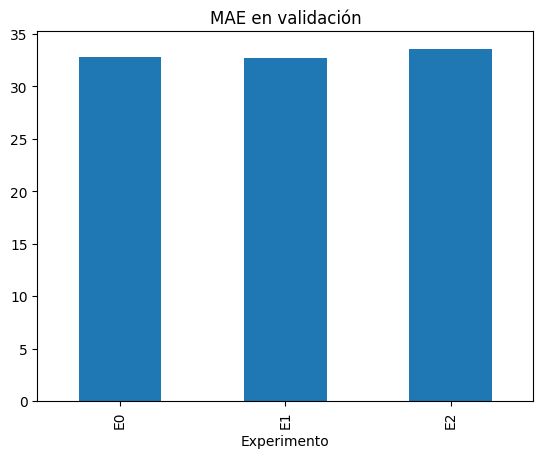

In [6]:
resultados=[]
for i in range(3):
    a=transformar(train.drop_duplicates() if i>=1 else train,i)
    b=transformar(val,i)
    columnas=cat[i]+num[i]
    modelo=crear_modelo(i)
    modelo.fit(a[columnas],a.duracion_min)
    metricas=medir(b.duracion_min,modelo.predict(b[columnas]))
    resultados.append({'Experimento':f'E{i}',**metricas})
tabla=pd.DataFrame(resultados)
display(tabla)
tabla.plot(x='Experimento',y='MAE',kind='bar',legend=False,title='MAE en validación');plt.show()

Modelo seleccionado: 1 Métricas finales: {'MAE': 31.117, 'RMSE': np.float64(38.331), 'R2': 0.1102}


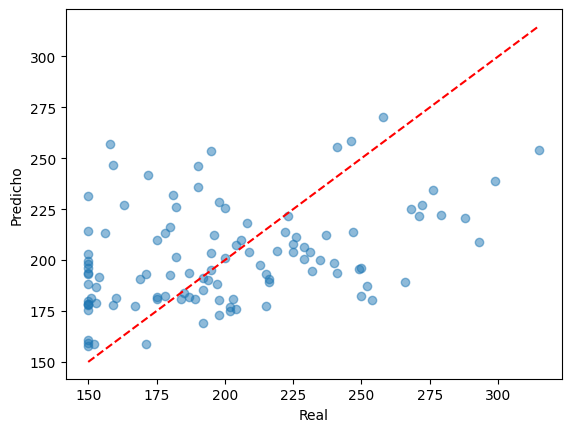

In [7]:
# Elegir por MAE de validación y evaluar UNA sola vez la prueba
mejor=int(tabla.loc[tabla.MAE.idxmin(),'Experimento'][1:])
train_val=pd.concat([train,val]).sort_values('fecha',kind='stable')
if mejor>=1:train_val=train_val.drop_duplicates()
a=transformar(train_val,mejor);b=transformar(test,mejor)
cols=cat[mejor]+num[mejor];final=crear_modelo(mejor)
final.fit(a[cols],a.duracion_min)
p=final.predict(b[cols])
print('Modelo seleccionado:',mejor,'Métricas finales:',medir(b.duracion_min,p))
plt.scatter(b.duracion_min,p,alpha=.5)
lo=min(b.duracion_min.min(),p.min());hi=max(b.duracion_min.max(),p.max())
plt.plot([lo,hi],[lo,hi],'r--');plt.xlabel('Real');plt.ylabel('Predicho');plt.show()